# 관계형 테이블과 키

**이 노트북에서 할 일**

1. 고객 표와 주문 표를 CSV 파일로 저장하고, 두 표를 잇는 고객 번호 열을 확인합니다.
2. 고객 번호로 두 표를 연결하고, 연결한 뒤에도 주문 행 수가 그대로인지 확인합니다.
3. 고객 번호가 두 번 적힌 고객 표로 연결해 행이 늘어나는 장면을 보고, 검사로 막습니다.

**준비물** — API 키 불필요. 고객 파일과 주문 파일은 노트북이 임시 폴더에 직접 만듭니다.
모델 호출은 0번이고 비용은 들지 않습니다. 실행 시간은 1분 이내입니다.

**기준 pandas 버전** — 01절과 같은 pandas 3.0.5를 씁니다. 실습 폴더에 고정한 버전입니다.
교재 출력도 이 버전(Python 3.12.13)으로 만들었습니다. 이 버전은 Python 3.11 이상에서 설치됩니다.
pandas 2 이하에서는 자료형 이름 같은 출력 모양이 다를 수 있고, 이번에 실행하지 않았습니다.

실습 폴더 `labs/part1/ch04-data-tools`에서 Ch 1 3절처럼 `uv sync --locked`로 환경을 만듭니다.
커널에서 이 폴더의 `.venv`를 고른 뒤 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

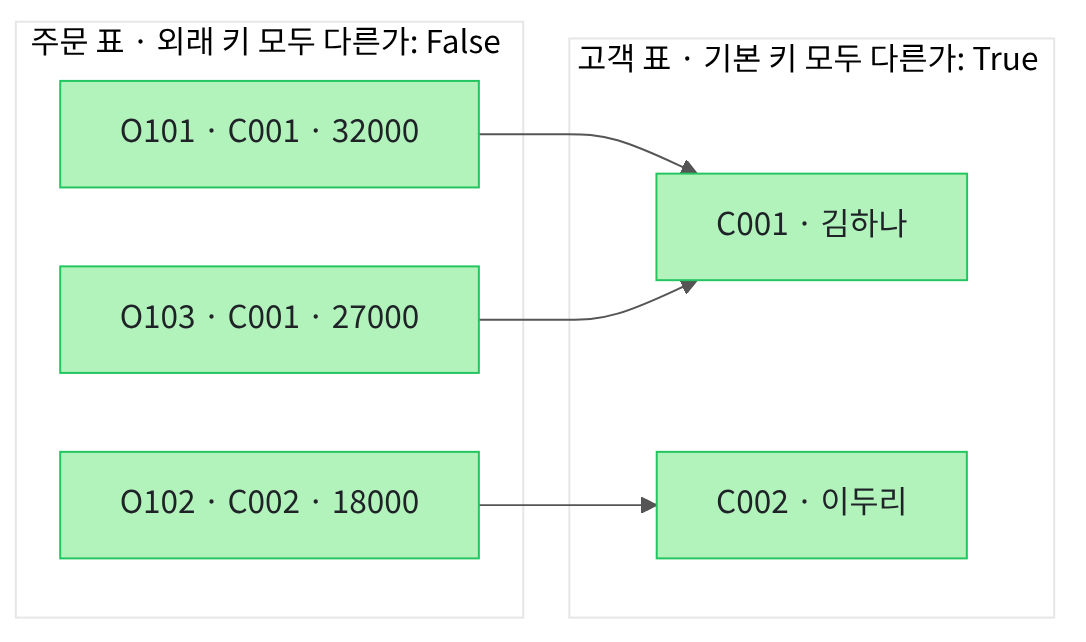

왼쪽 칸은 주문 표, 오른쪽 칸은 고객 표이고, 초록 상자 하나가 행 하나입니다.
화살표는 주문 행의 고객 번호가 가리키는 고객 행입니다. 주문 O101과 O103의 화살표가 모두 김하나 행으로 갑니다.
칸 제목 끝의 False와 True는 표마다 고객 번호가 모두 다른지 확인한 출력입니다.
주문 상자는 화살표가 겹치지 않게 O101, O103, O102 순서로 놓였습니다.

## 1. 준비

이 노트북은 CSV 파일 세 개를 만듭니다. 01절처럼 빈 임시 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다.
실습 폴더에는 파일이 생기지 않습니다.

코드의 import 두 줄은 Ch 2 07절에서 배운 import 문입니다. 표준 라이브러리 모듈 os와 tempfile을 불러옵니다.

In [1]:
# CSV 파일을 둘 빈 임시 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다
import os
import tempfile

# mkdtemp()는 운영체제 임시 폴더 안에 새 폴더를 만들고 그 경로를 반환합니다
practice_folder = tempfile.mkdtemp(prefix="ch04-02-")
# chdir()는 터미널의 cd처럼 현재 작업 폴더를 옮깁니다
os.chdir(practice_folder)
file_names = os.listdir()
print("현재 작업 폴더의 파일:", file_names)

현재 작업 폴더의 파일: []


**결과 읽기** — 현재 작업 폴더의 파일은 `[]`로, 빈 폴더에서 시작합니다.
폴더의 경로는 컴퓨터마다 달라서 출력하지 않았습니다.

## 2. pandas 불러오기

01절과 같은 줄 `import pandas as pd`로 pandas를 불러옵니다. 키워드 `as`는 불러온 모듈에 별명 pd를 붙입니다.
실행 전에 예상합니다. 01절과 같은 버전 3.0.5가 출력될 것입니다.

In [2]:
# 표 데이터를 다루는 pandas를 별명 pd로 불러옵니다
import pandas as pd

# 설치된 pandas 버전을 출력합니다
print("pandas 버전:", pd.__version__)

pandas 버전: 3.0.5


**결과 읽기** — `pandas 버전: 3.0.5`로 예상과 같습니다.
다른 버전이 나오면 커널이 실습 폴더의 `.venv`인지 확인합니다.

## 3. 고객 파일 만들기

이번 절은 표 두 개를 씁니다. 먼저 고객 두 명을 적은 `customers.csv`를 만듭니다.
열은 고객 번호 `customer_id`와 이름 `name`입니다.

고객 번호는 고객 한 명에게 하나씩 붙인 번호입니다. 이름이 같은 고객이 두 명 있어도 번호로 구분할 수 있습니다.
파일은 01절처럼 여러 줄 글 `"""…"""`와 `with open()` 블록으로 저장합니다.

실행 전에 예상합니다. 폴더 목록에 `customers.csv` 하나가 보일 것입니다.

In [3]:
# 고객 두 명을 CSV 글로 적어 customers.csv 파일에 저장합니다
customer_text = """customer_id,name
C001,김하나
C002,이두리
"""
with open("customers.csv", "w", encoding="utf-8") as file:
    file.write(customer_text)
file_names = os.listdir()
print("현재 작업 폴더의 파일:", file_names)

현재 작업 폴더의 파일: ['customers.csv']


**결과 읽기** — 현재 작업 폴더의 파일은 `['customers.csv']`로 예상과 같습니다.
이 파일은 열 이름 한 줄과 고객 두 줄, 모두 세 줄입니다.

## 4. 주문 파일 만들기

주문 파일은 01절의 주문 세 건과 같습니다. 다른 점은 둘째 열에 고객 번호 `customer_id`를 더한 것입니다.
주문 O101과 O103은 고객 C001, 주문 O102는 고객 C002의 주문입니다.

주문 줄에는 고객 이름을 적지 않고 번호만 적습니다. 이름은 고객 표 한 곳에만 둡니다.
그래야 고객 이름이 바뀌어도 고객 표의 한 줄만 고치면 됩니다.

폴더 목록은 Ch 2 03절의 `sorted()`로 정렬해 출력합니다. 운영체제마다 목록 순서가 다를 수 있기 때문입니다.
실행 전에 예상합니다. 폴더 목록에 파일 두 개가 보일 것입니다.

In [4]:
# 고객 번호 열을 더한 주문 세 건을 orders.csv 파일에 저장합니다
order_text = """order_id,customer_id,status,amount
O101,C001,paid,32000
O102,C002,pending,18000
O103,C001,paid,27000
"""
with open("orders.csv", "w", encoding="utf-8") as file:
    file.write(order_text)
# 파일 이름을 알파벳 순서로 정렬해 출력합니다
file_names = sorted(os.listdir())
print("현재 작업 폴더의 파일:", file_names)

현재 작업 폴더의 파일: ['customers.csv', 'orders.csv']


**결과 읽기** — 현재 작업 폴더의 파일은 `['customers.csv', 'orders.csv']`로 예상과 같습니다.
주문 파일은 열 이름 한 줄과 주문 세 줄입니다.

## 5. 두 표 읽기

두 파일을 01절의 `pd.read_csv()`로 읽어 표 두 개를 만듭니다.
실행 전에 예상합니다. 고객 표는 2행, 주문 표는 3행이고, 두 표 모두에 고객 번호 열이 있을 것입니다.

In [5]:
# 두 CSV 파일을 읽어 고객 표와 주문 표를 만듭니다
customers = pd.read_csv("customers.csv")
print("고객 표:")
print(customers)
orders = pd.read_csv("orders.csv")
print("주문 표:")
print(orders)

고객 표:
  customer_id name
0        C001  김하나
1        C002  이두리
주문 표:
  order_id customer_id   status  amount
0     O101        C001     paid   32000
1     O102        C002  pending   18000
2     O103        C001     paid   27000


**결과 읽기** — 라벨 줄 `고객 표:` 아래의 표는 `김하나`와 `이두리` 두 행입니다.
라벨 줄 `주문 표:` 아래의 표는 `O101`, `O102`, `O103` 세 행이고, 둘째 열이 `customer_id`입니다.

주문 표에서 고객 번호 `C001`은 0번과 2번 행에 두 번 나옵니다. 김하나 고객이 주문을 두 번 했다는 뜻입니다.
이름 `김하나`는 주문 표에 없고 고객 표에만 있습니다.

## 6. 기본 키와 외래 키 확인하기

표 안에서 행 하나를 구분하는 열을 기본 키(primary key)라고 부릅니다. 한 반의 출석 번호처럼 같은 번호가 두 사람에게 붙지 않습니다.
이 절의 고객 표에서는 고객 번호 열이 기본 키입니다. 그래서 고객 번호가 모두 달라야 합니다.

다른 표의 기본 키를 가리키는 열은 외래 키(foreign key)라고 부릅니다. 주문 표의 고객 번호 열이 외래 키입니다.
한 고객이 여러 번 주문할 수 있으므로, 외래 키에는 같은 번호가 여러 번 나와도 됩니다.

시리즈의 속성 `is_unique`에는 값이 모두 다르면 `True`, 겹치는 값이 있으면 `False`가 들어 있습니다.
실행 전에 예상합니다. 고객 표 쪽은 True, 주문 표 쪽은 C001이 두 번이라 False일 것입니다.

In [6]:
# 두 표의 고객 번호 열에 겹치는 값이 있는지 확인합니다
customer_ids = customers["customer_id"]
print("고객 표의 고객 번호가 모두 다른가:", customer_ids.is_unique)
# 주문 표의 고객 번호는 외래 키라 겹쳐도 됩니다
order_customer_ids = orders["customer_id"]
print("주문 표의 고객 번호가 모두 다른가:", order_customer_ids.is_unique)

고객 표의 고객 번호가 모두 다른가: True
주문 표의 고객 번호가 모두 다른가: False


**결과 읽기** — 첫 줄은 `고객 표의 고객 번호가 모두 다른가: True`로, 고객 번호가 기본 키 조건을 지킵니다.
둘째 줄은 `주문 표의 고객 번호가 모두 다른가: False`입니다. 외래 키는 겹쳐도 되므로 예상과 같습니다.

주문 여러 건이 고객 한 명을 가리키는 이 관계를 다대일(many-to-one) 관계라고 부릅니다.
주문 쪽이 「다(여럿)」, 고객 쪽이 「일(하나)」입니다.

## 7. 고객 번호로 두 표 연결하기

두 표에서 키 값이 같은 행끼리 열을 합치는 일을 조인(join)이라고 부릅니다. 주문 표의 메서드 `merge()`가 이 일을 합니다.
괄호에는 오른쪽에 붙일 표를 넣고, 키워드 인자 `on`에 비교할 열 이름을 적습니다.
Ch 3 02절의 `git merge`와 이름은 같지만, 여기서는 브랜치가 아니라 표 두 개를 합칩니다.

주문 행마다 고객 행이 하나씩 붙어야 합니다. 그래서 연결한 표의 행 수는 주문 표의 행 수와 같아야 합니다.
실행 전에 예상합니다. 주문 세 행 오른쪽에 이름 열이 붙고, 행 수는 3일 것입니다.

In [7]:
# 주문 표에 고객 표를 고객 번호로 연결합니다
joined = orders.merge(customers, on="customer_id")
print("연결한 표:")
print(joined)
print("주문 표의 행 수:", len(orders))
print("연결한 표의 행 수:", len(joined))
# 주문 한 건에 고객 한 명씩 붙었다면 행 수가 같습니다
assert len(joined) == len(orders)

연결한 표:
  order_id customer_id   status  amount name
0     O101        C001     paid   32000  김하나
1     O102        C002  pending   18000  이두리
2     O103        C001     paid   27000  김하나
주문 표의 행 수: 3
연결한 표의 행 수: 3


**결과 읽기** — 연결한 표의 오른쪽 끝에 이름 열 `name`이 붙었습니다.
고객 번호가 같은 `O101`과 `O103` 행에는 같은 이름 `김하나`가 들어갔습니다.
마지막 두 줄은 `주문 표의 행 수: 3`, `연결한 표의 행 수: 3`으로 예상과 같습니다.

## 8. 연결한 표에서 고객 이름으로 금액 모으기

이제 주문 표만으로는 답할 수 없던 질문에 답할 수 있습니다. 「김하나 고객의 주문 금액 합계는 얼마인가?」입니다.
01절의 마스크, `loc`, `sum()`을 연결한 표에 그대로 씁니다.

실행 전에 예상합니다. 김하나 고객의 주문은 O101 32000과 O103 27000이므로 합계는 59000일 것입니다.

In [8]:
# 연결한 표에서 이름이 김하나인 행의 금액만 꺼내 합계를 냅니다
name_mask = joined["name"] == "김하나"
kim_amounts = joined.loc[name_mask, "amount"]
print("김하나 고객의 금액:")
print(kim_amounts)
kim_total = kim_amounts.sum()
print("김하나 고객의 주문 합계:", kim_total)

김하나 고객의 금액:
0    32000
2    27000
Name: amount, dtype: int64
김하나 고객의 주문 합계: 59000


**결과 읽기** — 금액 시리즈에 `32000`과 `27000`이 인덱스 0, 2와 함께 남았습니다.
마지막 줄은 `김하나 고객의 주문 합계: 59000`으로 예상과 같습니다.
01절의 결제 완료 합계와 같은 숫자인 것은, 김하나 고객의 두 주문이 마침 모두 결제 완료이기 때문입니다.

## 9. 값 하나 바꿔 보기 — O103의 고객 번호를 C003으로

주문 O103의 고객 번호 하나만 `C001`에서 `C003`으로 바꿉니다. 고객 표에는 C003이 없습니다.
고객 등록보다 주문이 먼저 들어온 경우라고 생각합니다.

원래 표는 그대로 두려고, Ch 2 03절에서 목록에 쓴 메서드 `copy()`로 표를 복사합니다.
대입 줄 `changed_orders.loc[2, "customer_id"] = "C003"`은 01절에서 마스크를 넣던 자리에 인덱스 번호를 넣은 모양입니다.
대입 기호 왼쪽에 `loc[행, 열]`을 쓰면 그 칸을 읽지 않고 새 값을 저장합니다. 숫자 2는 주문 O103 행의 인덱스이고, 복사한 표만 바뀝니다.

메서드 `merge()`는 키워드 인자 `how`를 적지 않으면 양쪽 표에 모두 있는 키의 행만 남깁니다. 이 방식을 내부 조인(inner join)이라고 부릅니다.
실행 전에 예상합니다. 고객 번호 C003은 고객 표에 없으므로 O103 행이 빠지고, 연결한 표는 2행일 것입니다.

In [9]:
# 표를 복사해 O103의 고객 번호만 C003으로 바꾸고 다시 연결합니다
changed_orders = orders.copy()
changed_orders.loc[2, "customer_id"] = "C003"
changed_joined = changed_orders.merge(customers, on="customer_id")
print("연결한 표:")
print(changed_joined)
print("주문 표의 행 수:", len(changed_orders))
print("연결한 표의 행 수:", len(changed_joined))

연결한 표:
  order_id customer_id   status  amount name
0     O101        C001     paid   32000  김하나
1     O102        C002  pending   18000  이두리
주문 표의 행 수: 3
연결한 표의 행 수: 2


**결과 읽기** — 연결한 표에는 `O101`과 `O102` 두 행만 남았습니다.
행 수는 `주문 표의 행 수: 3`, `연결한 표의 행 수: 2`로 달라졌습니다.

오류는 나지 않았습니다. 고객을 찾지 못한 주문 O103이 조용히 빠졌습니다.
행 수를 비교하지 않으면 주문 하나가 사라진 줄 모르고 넘어갈 수 있습니다.

## 10. 왼쪽 조인으로 주문 행 모두 남기기

주문을 하나도 빼지 않으려면 키워드 인자 `how="left"`를 줍니다. 왼쪽 표인 주문 표의 행을 모두 남기는 왼쪽 조인(left join)입니다.
오른쪽 표에서 짝을 찾지 못한 칸은 값 없이 비워 둡니다.

실행 전에 예상합니다. 주문 세 행이 모두 남고, O103 행의 이름 칸만 비어 있을 것입니다.

In [10]:
# 왼쪽 표(주문 표)의 행을 모두 남기는 방식으로 같은 두 표를 연결합니다
left_joined = changed_orders.merge(customers, on="customer_id", how="left")
print("왼쪽 조인한 표:")
print(left_joined)
print("연결한 표의 행 수:", len(left_joined))
assert len(left_joined) == len(changed_orders)

왼쪽 조인한 표:
  order_id customer_id   status  amount name
0     O101        C001     paid   32000  김하나
1     O102        C002  pending   18000  이두리
2     O103        C003     paid   27000  NaN
연결한 표의 행 수: 3


**결과 읽기** — 행 수는 `연결한 표의 행 수: 3`으로, 주문이 모두 남았습니다.
고객 번호가 `C003`인 행의 이름 칸에는 `NaN`이 들어갔습니다.

값이 없는 칸에 pandas가 적는 표시가 NaN(not a number)입니다. 이런 칸을 결측값이라고 부릅니다.
앞 셀에서 행이 줄어든 원인이 이 빈 이름 칸으로 드러났습니다.

## 11. Before — 고객 번호가 두 번 적힌 고객 표로 연결하기

지난달 고객 목록과 이번 달 고객 목록을 한 파일로 이어 붙였다고 해 봅니다.
두 목록에 모두 있던 김하나 고객의 줄이 두 번 들어갔습니다.

이 파일을 `all_customers.csv`로 저장하고 표로 읽습니다.
실행 전에 예상합니다. 고객 표가 3행이 되고, C001 줄이 두 번 보일 것입니다.

In [11]:
# Before: C001 줄이 두 번 들어간 고객 파일을 만들어 표로 읽습니다
all_customer_text = """customer_id,name
C001,김하나
C002,이두리
C001,김하나
"""
with open("all_customers.csv", "w", encoding="utf-8") as file:
    file.write(all_customer_text)
all_customers = pd.read_csv("all_customers.csv")
print("고객 표:")
print(all_customers)

고객 표:
  customer_id name
0        C001  김하나
1        C002  이두리
2        C001  김하나


**결과 읽기** — 인덱스 0과 2인 두 행이 모두 `C001`, `김하나`입니다.
이 표의 고객 번호는 더 이상 기본 키 조건을 지키지 못합니다.

이 고객 표에 앞의 주문 표를 연결하고 행 수를 봅니다.
실행 전에 예상합니다. 주문은 세 건이므로, 행 수 3이 나와야 맞습니다.

In [12]:
# Before: 고객 번호가 겹치는 고객 표에 주문 표를 연결합니다
wrong_joined = orders.merge(all_customers, on="customer_id")
print("연결한 표:")
print(wrong_joined)
print("주문 표의 행 수:", len(orders))
print("연결한 표의 행 수:", len(wrong_joined))

연결한 표:
  order_id customer_id   status  amount name
0     O101        C001     paid   32000  김하나
1     O101        C001     paid   32000  김하나
2     O102        C002  pending   18000  이두리
3     O103        C001     paid   27000  김하나
4     O103        C001     paid   27000  김하나
주문 표의 행 수: 3
연결한 표의 행 수: 5


**결과 읽기** — 예상과 달리 마지막 줄은 `연결한 표의 행 수: 5`입니다.
표를 보면 주문 `O101`과 `O103`이 두 줄씩 나옵니다.
주문 한 건이 같은 번호의 고객 행 두 개와 각각 짝지어졌기 때문입니다.

행이 늘면 금액 합계도 달라집니다. 원래 주문 표와 연결한 표의 금액 합계를 비교합니다.
실행 전에 예상합니다. 주문 표의 합계는 01절과 같은 77000일 것입니다.

In [13]:
# Before: 원래 주문 표와 연결한 표의 금액 합계를 비교합니다
original_total = orders["amount"].sum()
print("주문 표의 금액 합계:", original_total)
wrong_total = wrong_joined["amount"].sum()
print("연결한 표의 금액 합계:", wrong_total)

주문 표의 금액 합계: 77000
연결한 표의 금액 합계: 136000


**결과 읽기** — 첫 줄은 `주문 표의 금액 합계: 77000`이고, 둘째 줄은 `연결한 표의 금액 합계: 136000`입니다.
늘어난 59000은 두 번 들어간 O101 32000과 O103 27000을 더한 값입니다.

셀은 오류 없이 끝났습니다. 이 표로 매출을 보고하면 김하나 고객의 주문이 두 배로 잡힙니다.

## 12. After — 연결할 때 관계를 검사하고, 겹친 줄 지우기

메서드 `merge()`에 키워드 인자 `validate="many_to_one"`을 주면, 연결한 표를 만들기 전에 키를 검사합니다.
왼쪽 표의 키는 겹쳐도 되고, 오른쪽 표의 키는 모두 달라야 한다는 검사입니다. 6절에서 본 다대일 관계를 그대로 적은 값입니다.

검사를 통과하지 못하면 pandas는 오류 MergeError를 냅니다. 이 오류 이름은 pandas 안의 errors 모듈에 있습니다.
그래서 `pd.errors.MergeError`처럼 점으로 이어 적습니다. Ch 2 05절처럼 이 오류 이름만 받는 `try/except`로 감쌉니다.

실행 전에 예상합니다. 고객 번호 C001이 겹치므로 오류 메시지가 출력될 것입니다.

In [14]:
# After: 다대일 관계를 검사하며 같은 두 표를 연결해 봅니다
try:
    orders.merge(all_customers, on="customer_id", validate="many_to_one")
except pd.errors.MergeError as error:
    print("연결 오류:", error)

연결 오류: Merge keys are not unique in right dataset; not a many-to-one merge

Duplicates in right:
 customer_id
       C001 ...


**결과 읽기** — 첫 줄은 `연결 오류: Merge keys are not unique in right dataset; not a many-to-one merge`입니다.
오른쪽 표의 키가 겹쳐서 다대일 연결이 아니라는 뜻입니다.
아래 `Duplicates in right:` 줄 밑에는 겹친 고객 번호 `C001`이 보입니다.

틀린 표를 만들기 전에 연결 단계에서 멈췄습니다. 5행짜리 표와 틀린 합계는 만들어지지 않습니다.

이제 고객 표에서 겹친 줄을 지웁니다. 메서드 `drop_duplicates()`는 앞에 이미 나온 줄과 모든 열의 값이 같은 줄을 지운 새 표를 반환합니다.
인자를 주지 않으면 처음 나온 줄을 남깁니다.

지운 뒤에는 `is_unique`로 고객 번호가 모두 다른지 다시 확인합니다.
실행 전에 예상합니다. 인덱스 2인 줄이 사라지고 `True`가 나올 것입니다.

In [15]:
# After: 모든 열이 같은 겹친 줄을 지우고, 고객 번호가 모두 다른지 확인합니다
unique_customers = all_customers.drop_duplicates()
print("겹친 줄을 지운 고객 표:")
print(unique_customers)
unique_ids = unique_customers["customer_id"]
print("고객 번호가 모두 다른가:", unique_ids.is_unique)

겹친 줄을 지운 고객 표:
  customer_id name
0        C001  김하나
1        C002  이두리
고객 번호가 모두 다른가: True


**결과 읽기** — 인덱스 0과 1인 `김하나`, `이두리` 두 줄만 남았습니다.
마지막 줄은 `고객 번호가 모두 다른가: True`로 예상과 같습니다.

검사 인자를 그대로 둔 채 다시 연결합니다.
실행 전에 예상합니다. 오류 없이 3행이 되고, 금액 합계는 77000일 것입니다.

In [16]:
# After: 겹친 줄을 지운 고객 표에 다대일 검사를 켜고 다시 연결합니다
fixed_joined = orders.merge(unique_customers, on="customer_id", validate="many_to_one")
print("연결한 표의 행 수:", len(fixed_joined))
fixed_total = fixed_joined["amount"].sum()
print("연결한 표의 금액 합계:", fixed_total)
assert len(fixed_joined) == len(orders)
assert fixed_total == 77000

연결한 표의 행 수: 3
연결한 표의 금액 합계: 77000


**결과 읽기** — 출력은 `연결한 표의 행 수: 3`과 `연결한 표의 금액 합계: 77000`입니다.
검사 줄 `assert` 두 개도 멈추지 않았습니다. 주문 행 수와 합계가 원래 주문 표와 같아졌습니다.

## 정리

- 기본 키는 표 안에서 행 하나를 구분하는 열이라 값이 겹치면 안 됩니다. 외래 키는 다른 표의 기본 키를 가리키고, 겹쳐도 됩니다.
- 메서드 `merge()`로 연결한 뒤에는 행 수를 주문 표와 비교합니다. 짝 없는 키는 행을 줄였고, 겹친 키는 행을 늘렸습니다.
- 키워드 인자 `validate="many_to_one"`은 오른쪽 표의 키가 겹치면 연결을 멈춥니다.

이번에는 Linux의 pandas 3.0.5로 실행했습니다. 다른 운영체제에서는 실행하지 않았습니다.
다음 절에서는 같은 고객 표와 주문 표를 SQLite 데이터베이스에 만들고, SQL 문장으로 고객 주문을 조회합니다.